In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import gzip

# Exercice 1 : Entropie et compression des données
Dans cet exercice, nous introduisons la notion d'entropie au sens de la théorie de l'information développée par Claude Shannon. L'objectif est de lier mathématiquement la "surprise" générée par un événement aléatoire à l'incertitude globale d'un système, afin de poser les bases théoriques nécessaires à la compréhension de la compression de données.

## Partie I : Surprise, incertitude et information

## Question 1 : Expression générale de l'incertitude et application

L'incertitude $H[X]$ est définie par Shannon comme la "surprise moyenne". En termes probabilistes, il s'agit de l'espérance mathématique de la surprise $\log_2(1/p_i)$ sur l'ensemble des résultats possibles. 

L'expression générale s'écrit donc :
$$H[X] = \mathbb{E}\left[\log_2\left(\frac{1}{p(X)}\right)\right] = \sum_{i} p_i \log_2\left(\frac{1}{p_i}\right)$$

On applique cette formule à l'alphabet $\chi = \{A, B, C, D\}$ avec les probabilités $p_A=1/2$, $p_B=1/4$, $p_C=1/8$, $p_D=1/8$.

$$H[X] = \frac{1}{2}\log_2\left(\frac{1}{1/2}\right) + \frac{1}{4}\log_2\left(\frac{1}{1/4}\right) + \frac{1}{8}\log_2\left(\frac{1}{1/8}\right) + \frac{1}{8}\log_2\left(\frac{1}{1/8}\right)$$


$$H[X] = \frac{1}{2}(1) + \frac{1}{4}(2) + \frac{1}{8}(3) + \frac{1}{8}(3)$$

$$H[X] = \frac{1}{2} + \frac{2}{4} + \frac{6}{8} = 1.75 \text{ bits}$$

L'incertitude de cet alphabet est de 1.75 bits par tirage en moyenne.

## Question 2 : Démonstration des bornes de l'incertitude

**1. Borne inférieure ($H[X] \ge 0$)**

Par définition, une probabilité $p_i$ est comprise dans l'intervalle $]0, 1]$. Par conséquent, son inverse vérifie :
$$ \frac{1}{p_i} \ge 1 $$

La fonction logarithme en base 2 étant strictement croissante, on en déduit que la surprise est toujours positive ou nulle :
$$ \log_2\left(\frac{1}{p_i}\right) \ge 0 $$

L'incertitude $H[X]$ étant une somme pondérée de termes positifs ou nuls (car $p_i \ge 0$), elle est nécessairement positive ou nulle :
$$ H[X] = \sum_{i=1}^L p_i \log_2\left(\frac{1}{p_i}\right) \ge 0 $$

La valeur $0$ est atteinte si et seulement si une seule lettre $k$ a une probabilité $p_k = 1$ (donnant $\log_2(1) = 0$), toutes les autres ayant une probabilité nulle.

**2. Borne supérieure ($H[X] \le \log_2 L$)**

La fonction logarithme $f(x) = \log_2(x)$ est une fonction strictement concave. On peut donc appliquer l'inégalité de Jensen, qui énonce que l'espérance de la fonction est inférieure ou égale à la fonction de l'espérance :
$$ \sum_{i=1}^L p_i f(x_i) \le f\left(\sum_{i=1}^L p_i x_i\right) $$

En posant $x_i = \frac{1}{p_i}$, on obtient pour l'entropie :
$$ H[X] = \sum_{i=1}^L p_i \log_2\left(\frac{1}{p_i}\right) \le \log_2\left(\sum_{i=1}^L p_i \cdot \frac{1}{p_i}\right) $$

On simplifie l'argument du logarithme dans le terme de droite :
$$ p_i \cdot \frac{1}{p_i} = 1 \implies \sum_{i=1}^L 1 = L $$

Ce qui démontre directement la borne supérieure :
$$ H[X] \le \log_2(L) $$

Pour une fonction strictement concave, l'inégalité de Jensen devient une égalité si et seulement si tous les arguments $x_i$ sont égaux. Il faut donc que $\frac{1}{p_i}$ soit constant, ce qui implique que toutes les lettres sont équiprobables : $p_i = \frac{1}{L}$.

## Question 3 : Valeur moyenne de l'information manquante

Par définition dans l'énoncé, l'information manquante associée à une mesure spécifique $x_i$ est donnée par la formule $\log_2(1/p_i)$. 

Pour trouver la valeur moyenne de cette information manquante sur l'ensemble du système, il faut calculer son espérance. On multiplie la quantité d'information de chaque événement par sa probabilité d'occurrence $p_i$, puis on fait la somme sur toutes les lettres de l'alphabet :

$$ \mathbb{E}[\text{Information manquante}] = \sum_{i=1}^L p_i \log_2\left(\frac{1}{p_i}\right) $$

On reconnaît l'expression mathématique de l'incertitude $H[X]$ démontrée à la question 1. On en conclut donc que la valeur moyenne de l'information manquante est égale à l'entropie du système :
$$ \mathbb{E}[\text{Information manquante}] = H[X] $$

Pour l'alphabet $\chi = \{A, B, C, D\}$ avec les probabilités données, la valeur moyenne de l'information manquante est :
$$ \mathbb{E}[\text{Information manquante}] = 1.75 \text{ bits} $$

## Partie II : Entropie de Shannon et Questions OUI/NON

## Question 1 : Nombre moyen de questions posées pour trouver la lettre tirée

**Stratégie de résolution :**
À chaque étape, la démarche optimale consiste à formuler une question fermée (OUI/NON) qui scinde l'espace des événements restants en deux sous-ensembles dont les probabilités cumulées sont les plus proches possibles de $\frac{1}{2}$. 

**Arbre de décision :**
1. Cette lettre appartient-elle au sous-ensemble $\{B, C, D\}$ ?
   - **Non** : La lettre est $A$. Le nombre de questions posées est $N_{A} = 1$.
   - **Oui** : La lettre appartient-elle au sous-ensemble $\{C, D\}$ ?
     - **Non** : La lettre est $B$. Le nombre de questions posées est $N_{B} = 2$.
     - **Oui** : La lettre est-elle $D$ ?
       - **Non** : La lettre est $C$. Le nombre de questions posées est $N_{C} = 3$.
       - **Oui** : La lettre est $D$. Le nombre de questions posées est $N_{D} = 3$.

**Calcul du nombre moyen de questions $\langle N \rangle$ :**
L'espérance du nombre de questions s'obtient en pondérant le nombre de questions nécessaires pour chaque issue par la probabilité d'occurrence de cette issue.
$$ \langle N \rangle = \sum_{i \in \{A,B,C,D\}} p_{i} N_{i} = p_{A}N_{A} + p_{B}N_{B} + p_{C}N_{C} + p_{D}N_{D} $$
En substituant les valeurs numériques :
$$ \langle N \rangle = \left(\frac{1}{2} \cdot 1\right) + \left(\frac{1}{4} \cdot 2\right) + \left(\frac{1}{8} \cdot 3\right) + \left(\frac{1}{8} \cdot 3\right) = \frac{1}{2} + \frac{1}{2} + \frac{6}{8} = 1 + \frac{3}{4} = 1,75 $$

Le nombre moyen de questions à formuler pour identifier la lettre tirée de manière certaine est de $1,75$. Cette valeur correspond exactement à la valeur de l'entropie $H[X]$ calculée dans la partie I. L'incertitude initiale du système équivaut au nombre moyen d'opérations binaires nécessaires pour la lever.


## Question 2 : Nombre moyen de questions pour un alphabet de $2^b$ lettres

**Stratégie de résolution :**
L'alphabet est composé de $2^{b}$ lettres équiprobables. La stratégie optimale consiste à diviser récursivement l'espace des événements en deux moitiés égales.
La première question sera du type : "La lettre tirée appartient-elle au sous-ensemble $\{x_{1}, x_{2}, \dots, x_{2^{b-1}}\}$ ?". 
Les questions successives diviseront l'espace de recherche par deux à chaque itération.

**Calcul du nombre moyen de questions $\langle N \rangle$ :**
À chaque étape, la probabilité cumulée des deux sous-ensembles est exactement $1/2$. Étant donné la taille initiale de l'alphabet de $2^{b}$, il est nécessaire d'effectuer exactement $b$ divisions par deux pour isoler n'importe quelle lettre. 
Par conséquent, le nombre de questions requises est constant et vaut $N_{i} = b$ pour toute lettre $i \in \{1, \dots, 2^{b}\}$.
La probabilité d'occurrence de chaque lettre est $p_{i} = \frac{1}{2^{b}}$.

Le calcul de l'espérance s'établit ainsi :
$$ \langle N \rangle = \sum_{i=1}^{2^{b}} p_{i} N_{i} = \sum_{i=1}^{2^{b}} \left( \frac{1}{2^{b}} \right) b = 2^{b} \cdot \left( \frac{b}{2^{b}} \right) = b $$

Le nombre moyen de questions à poser est donc de $b$.

**Calcul de l'entropie du système $H[X]$ :**
L'incertitude initiale se calcule via la définition de Shannon :
$$ H[X] = \sum_{i=1}^{2^{b}} p_{i} \log_{2}\left(\frac{1}{p_{i}}\right) = \sum_{i=1}^{2^{b}} \left( \frac{1}{2^{b}} \right) \log_{2}(2^{b}) $$
Sachant que $\log_{2}(2^{b}) = b$ :
$$ H[X] = \sum_{i=1}^{2^{b}} \left( \frac{1}{2^{b}} \right) b  = 2^{b} \cdot \left( \frac{b}{2^{b}} \right) = b $$

La comparaison des deux résultats confirme que $\langle N \rangle = H[X]$. L'espérance du nombre de questions binaires nécessaires pour identifier la valeur de la variable aléatoire est égale à l'entropie (incertitude) de ce système.

## Question 3 : Théorème de Shannon

**Généralisation de la stratégie :**
Selon l'hypothèse de l'énoncé, il est toujours possible de diviser l'ensemble des lettres en deux groupes de probabilités égales à $1/2$. La stratégie se généralise ainsi :
1. La première question vérifie si la lettre appartient à un sous-ensemble $\{x_{1}, \dots, x_{j}\}$ tel que $\sum_{i=1}^{j} p_{i} = \frac{1}{2}$.
2. Si la réponse est affirmative, la question suivante teste l'appartenance à un sous-ensemble $\{x_{1}, \dots, x_{k}\}$ tel que $\sum_{i=1}^{k} p_{i} = \frac{1}{4}$.
3. Si la réponse est négative, la recherche se poursuit dans le sous-ensemble complémentaire $\{x_{j+1}, \dots, x_{l}\}$ tel que $\sum_{i=j+1}^{l} p_{i} = \frac{1}{4}$.
Le processus est itéré jusqu'à l'isolement complet de la lettre tirée.

**Calcul analytique du nombre moyen de questions $\langle N \rangle$ :**
À la $n$-ième question, l'espace des événements est réduit à un sous-ensemble dont la probabilité cumulée est $p = \frac{1}{2^{n}}$.
L'algorithme s'arrête pour une lettre spécifique $x_{i}$ après $N_{i}$ questions. À ce stade, le sous-ensemble restant est le singleton $\{x_{i}\}$, dont la probabilité intrinsèque est $p_{i}$.
Par identification :
$$ p_{i} = \frac{1}{2^{N_{i}}} $$
En isolant $N_{i}$, on obtient le nombre de questions nécessaires pour la lettre $x_{i}$ :
$$ 2^{N_{i}} = \frac{1}{p_{i}} \iff N_{i} = \log_{2}\left(\frac{1}{p_{i}}\right) $$

L'espérance du nombre de questions posées sur l'ensemble de l'alphabet de taille $A$ s'écrit :
$$ \langle N \rangle = \sum_{i=1}^{A} p_{i} N_{i} = \sum_{i=1}^{A} p_{i} \log_{2}\left(\frac{1}{p_{i}}\right) $$

L'expression obtenue correspond formellement à la définition de l'entropie de Shannon $H[X]$. Il est ainsi démontré que pour cet alphabet général, le nombre moyen de questions fermées requises pour déterminer la valeur de la variable aléatoire est strictement égal à l'entropie du système :
$$ \langle N \rangle = H[X] $$

## Partie III : Compression de données

On dispose d'un fichier de $N$ valeurs aléatoires $x_i \in \chi$ avec $\chi$ l'alphabet contenant $L$ lettres. Ce fichier prend un place $N \log_{2} L$ bits sur le disque dur.

## Question 1 : Taille du fichier et facteur de compression

**Taille du nouveau fichier compressé :**
La stratégie d'encodage consiste à remplacer l'enregistrement direct de chaque lettre par la séquence des réponses (OUI/NON) nécessaires à son identification.
Étant donné qu'une réponse à une question fermée correspond à une valeur binaire (0 ou 1), formuler une question équivaut à allouer exactement 1 bit d'information.

Le fichier initial contient $N$ valeurs. D'après les résultats de la partie II, le nombre moyen de questions (et donc de bits) nécessaires pour encoder une valeur $x_{i}$ est donné par l'espérance $\langle N \rangle = H[X]$.
La taille totale attendue pour le nouveau fichier compressé s'exprime donc par le produit :
$$ \text{Taille compressée} = N \cdot \langle N \rangle = N \cdot \sum_{i=1}^{L} p_{i} \log_{2}\left(\frac{1}{p_{i}}\right) \text{ bits} $$

**Facteur de compression :**
Le facteur de compression, noté $f_{c}$, est défini comme le rapport entre la taille du fichier avant compression et sa taille après compression. 
Le fichier non compressé occupe $N \log_{2}(L)$ bits.
L'expression de $f_{c}$ s'établit ainsi :
$$ f_{c} = \frac{N \log_{2}(L)}{N \sum_{i=1}^{L} p_{i} \log_{2}\left(\frac{1}{p_{i}}\right)} = \frac{\log_{2}(L)}{\sum_{i=1}^{L} p_{i} \log_{2}\left(\frac{1}{p_{i}}\right)} = \frac{\log_{2}(L)}{H[X]} $$

## Question 2 : Comparez ce résultat avec les performances de notre programme de compression


Avant de comparer, on remarque à la Q1 que j'ai établi un facteur de compression
log₂(L)/H, qui compare l'entropie à un encodage optimal à longueur fixe sur L
lettres. Mais les fichiers sont stockés en ASCII, c'est-à-dire sur 8 bits par
caractère quelle que soit la taille de l'alphabet. C'est donc 8/H qu'il faut
confronter aux performances de gzip.

Les deux quantités ne mesurent pas la même chose : log₂(L)/H ne capture que le
gain dû à la non-uniformité des probabilités, ce qui explique qu'il vaille 1
pour uniform.txt, half.txt et abcd.txt, dont les lettres sont équiprobables, et
1.14 seulement pour abcd2.txt. Le rapport 8/H y ajoute le gain dû au fait que
l'alphabet est plus petit que les 256 caractères que l'ASCII permettrait.

In [ ]:
fichiers = ['uniform.txt', 'half.txt', 'abcd.txt', 'abcd2.txt']
entropies_theoriques = [8.0, 7.0, 2.0, 1.75]
tailles_alphabet = [256, 128, 4, 4]

print("Comparaison des performances de compression")
print("-" * 92)
print(f"{'Fichier':<15} | {'Taille Init. (o)':<16} | {'Taille Comp. (o)':<16} | "
      f"{'Ratio Exp.':<12} | {'8/H':<8} | {'log2(L)/H':<10}")
print("-" * 92)

for fichier, H, L in zip(fichiers, entropies_theoriques, tailles_alphabet):
    if not os.path.exists(fichier):
        print(f"Erreur : Le fichier '{fichier}' est introuvable. "
              f"Place-le dans le même dossier que le notebook.")
        continue

    taille_initiale = os.path.getsize(fichier)

    fichier_compresse = fichier + '.gz'
    with open(fichier, 'rb') as f_in:
        with gzip.open(fichier_compresse, 'wb') as f_out:
            f_out.writelines(f_in)

    taille_compressee = os.path.getsize(fichier_compresse)

    ratio_experimental = taille_initiale / taille_compressee
    ratio_ascii = 8.0 / H
    ratio_fixe = np.log2(L) / H

    print(f"{fichier:<15} | {taille_initiale:<16} | {taille_compressee:<16} | "
          f"{ratio_experimental:<12.2f} | {ratio_ascii:<8.2f} | {ratio_fixe:<10.2f}")

    os.remove(fichier_compresse)

Comparaison des performances de compression
--------------------------------------------------------------------------------------------
Fichier         | Taille Init. (o) | Taille Comp. (o) | Ratio Exp.   | 8/H      | log2(L)/H 
--------------------------------------------------------------------------------------------
uniform.txt     | 10000            | 10035            | 1.00         | 1.00     | 1.00      
half.txt        | 10000            | 8848             | 1.13         | 1.14     | 1.00      
abcd.txt        | 10000            | 3238             | 3.09         | 4.00     | 1.00      
abcd2.txt       | 10000            | 2908             | 3.44         | 4.57     | 1.14      


Le cas de uniform.txt est le plus net : le fichier ne se compresse pas du tout,
il grossit même un peu (10 000 → 10 035 octets). C'est logique, puisque les 256
caractères sont équiprobables et que H vaut donc 8 bits, soit exactement ce que
coûte déjà un caractère ASCII. Il n'y a rien à gagner, et les 35 octets en trop
sont juste l'en-tête que gzip ajoute au passage.

half.txt marche beaucoup mieux : 1.13 mesuré contre 1.14 attendu, donc gzip est
pratiquement à la borne. Ça n'a rien d'étonnant, 128 vaut 2^7 et le code de
Huffman tombe pile sur 7 bits par caractère.

Le cas intéressant, c'est abcd.txt et abcd2.txt, où l'écart devient important
(3.09 contre 4.00, et 3.44 contre 4.57). C'est un peu surprenant : ce sont les
fichiers les plus compressibles, et pourtant c'est là que gzip est le plus loin
de la limite.

En cherchant, l'explication tient à la façon dont gzip est construit. Il fait
d'abord passer les données dans LZ77, qui repère les répétitions, puis seulement
après applique Huffman. Or ici Huffman seul serait déjà optimal : avec 4 lettres
équiprobables on a 2 bits par lettre, c'est-à-dire H exactement. Le problème
vient de LZ77 : sur un alphabet aussi petit, trois caractères de suite se
répètent par hasard une fois sur 64, donc LZ77 trouve énormément de
"répétitions" qui n'en sont pas vraiment, et les remplace par un couple
(longueur, distance) qui coûte plus cher que les 6 bits qu'il remplace.

Autrement dit, gzip paie un étage de recherche de répétitions qui ne sert à rien
sur des données tirées au hasard, et qui lui coûte même des bits. D'autres
compresseurs construits différemment, comme bzip2 qui repose sur la transformée
de Burrows-Wheeler, n'ont pas ce problème.

Ce qu'il faut en retenir, c'est que H est une borne pour un compresseur idéal,
pas une prédiction de ce que va donner un vrai compresseur. gzip est pensé pour
du texte, où les répétitions sont réelles ; sur des données tirées au hasard
dans un petit alphabet, il cherche une structure qui n'existe pas. Pour
s'approcher vraiment de H, il faudrait un codage qui colle à la distribution des
symboles, comme un codage arithmétique d'ordre 0.

## Partie IV : L'entropie de l'anglais

## Question 1 : Rapport de compression de l'anglais

In [ ]:
freqs_lettres = {
    'a': 0.08167, 'b': 0.01492, 'c': 0.02782, 'd': 0.04253, 'e': 0.12702,
    'f': 0.02228, 'g': 0.02015, 'h': 0.06094, 'i': 0.06966, 'j': 0.00153,
    'k': 0.00772, 'l': 0.04025, 'm': 0.02406, 'n': 0.06749, 'o': 0.07507,
    'p': 0.01929, 'q': 0.00095, 'r': 0.05987, 's': 0.06327, 't': 0.09056,
    'u': 0.02758, 'v': 0.00978, 'w': 0.02360, 'x': 0.00150, 'y': 0.01974,
    'z': 0.00074
}

probabilites = np.array(list(freqs_lettres.values()))
probabilites = probabilites / np.sum(probabilites)
entropie_anglais = -np.sum(probabilites * np.log2(probabilites))
ratio_compression = 8.0 / entropie_anglais

print(f"Entropie de l'anglais (26 lettres) : {entropie_anglais:.3f} bits/caractère")
print(f"Rapport de compression théorique   : {ratio_compression:.3f}")


Entropie de l'anglais (26 lettres) : 4.176 bits/caractère
Rapport de compression théorique   : 1.916


En utilisant les probabilités d'apparition des 26 lettres de l'alphabet en négligeant les espaces et la ponctuation, l'entropie de Shannon calculée est $H \approx 4.18$ bits par caractère. 

Si l'on considère qu'un texte initial est encodé en ASCII classique où chaque lettre occupe 8 bits, la théorie de l'information nous indique que nous pouvons au mieux compresser ce texte à une moyenne de $4.18$ bits par lettre. 

Le rapport de compression théorique maximal pour l'anglais, basé uniquement sur la fréquence individuelle des lettres, est donc le ratio entre l'encodage initial et l'entropie :
$$ \text{Rapport de compression} = \frac{8}{H} \approx 1.92 $$

Cela signifie qu'en utilisant un compresseur parfait basé sur la fréquence des lettres, on pourrait réduire la taille d'un texte anglais d'environ la moitié.

## Question 2 : Comparaison avec les meilleurs compresseurs (Hutter Prize)


In [ ]:
taille_initiale_octets = 1_000_000_000  
taille_compressee_record = 100_424_672

ratio_hutter = taille_initiale_octets / taille_compressee_record
bits_par_caractere_hutter = 8.0 / ratio_hutter

entropie_q1 = entropie_anglais
ratio_q1 = ratio_compression

print("=== Comparaison des performances de compression ===")
print(f"1. Modèle théorique Q1 (Ordre 0) : {entropie_q1:.3f} bits/lettre | Ratio = {ratio_q1:.2f}")
print(f"2. Record Hutter Prize (IA)      : {bits_par_caractere_hutter:.3f} bits/lettre | Ratio = {ratio_hutter:.2f}")
print("-" * 65)
print(f"-> Le Hutter Prize compresse environ {ratio_hutter / ratio_q1:.1f} fois mieux que notre limite théorique.")



=== Comparaison des performances de compression ===
1. Modèle théorique Q1 (Ordre 0) : 4.176 bits/lettre | Ratio = 1.92
2. Record Hutter Prize (IA)      : 0.803 bits/lettre | Ratio = 9.96
-----------------------------------------------------------------
-> Le Hutter Prize compresse environ 5.2 fois mieux que notre limite théorique.



Source : le record actuel sur enwik9 ($10^{9}$ octets) est de
$100\,424\,672$ octets, obtenu par V. Ivanov avec fx2-cmix-T le 24 juillet 2026
([prize.hutter1.net](http://prize.hutter1.net/)).


Le *Hutter Prize* est une compétition d'intelligence artificielle récompensant les algorithmes capables de compresser un fichier texte spécifique de 1 Go issu de Wikipédia en anglais. 
Actuellement, les meilleurs compresseurs au monde parviennent à réduire ce fichier à environ 100 Mo. Cela représente un rapport de compression d'environ 10 (soit environ 0.8 bit par caractère). 

C'est environ 5 fois plus performant que le rapport théorique de $1.92$ (soit $4.18$ bits par caractère) que nous avons calculé à la question 1.

Notre programme de la Q1 indique qu'on ne pourrait pas descendre en dessous de $\sim 4.18$ bits par caractère, pourtant les vainqueurs du Hutter Prize descendent sous la barre des $1$ bit par caractère. 

Cette différence fondamentale vient de notre hypothèse de départ : notre calcul de l'entropie à la Q1 est un modèle d'ordre 0. Il suppose que chaque lettre est tirée de manière totalement indépendante, sans tenir compte de ses voisines. 

Or, les langues humaines sont extrêmement structurées et contiennent une énorme quantité de redondances, ce qui fait chuter son incertitude :
1. Redondance syntaxique et N-grammes : Les lettres ne se suivent pas au hasard. Après un 'q', la lettre 'u' est presque certaine. Le groupe 'th' ou 'ing' apparaît constamment en anglais. L'entropie locale de ces lettres est donc quasi nulle.
2. Vocabulaire et grammaire : L'anglais utilise des mots définis par un dictionnaire fini et des règles de syntaxe prévisibles. Si on lit "It is raining cats and ", le mot "dogs" est parfaitement prévisible (aucune surprise).
3. Contexte global (sémantique) : Un article Wikipédia sur l'astronomie utilisera le mot "star" avec une probabilité beaucoup plus forte que la moyenne de la langue anglaise.

Les algorithmes qui gagnent le Hutter Prize ne sont pas de simples zippeurs. Ce sont des modèles de traitement du langage qui prédisent dynamiquement la suite du texte en fonction du contexte. En prédisant correctement ce qui va suivre, ils réduisent drastiquement l'incertitude, ce qui leur permet de contourner la limite de $4.18$ bits et de s'approcher de la véritable entropie de l'anglais qui est estimée à environ 1 bit par caractère.

## Question 3 : Estimation de l'entropie par l'expérience interactive


Essais totaux       : 122 pour 34 caractères (3.59 par caractère)
Devinés du 1er coup : 23 sur 34
Bornes données par l'expérience : 1.2178 – 1.7921 bits/caractère
Modèle d'ordre 0 (Q1)           : 4.1758 bits/caractère


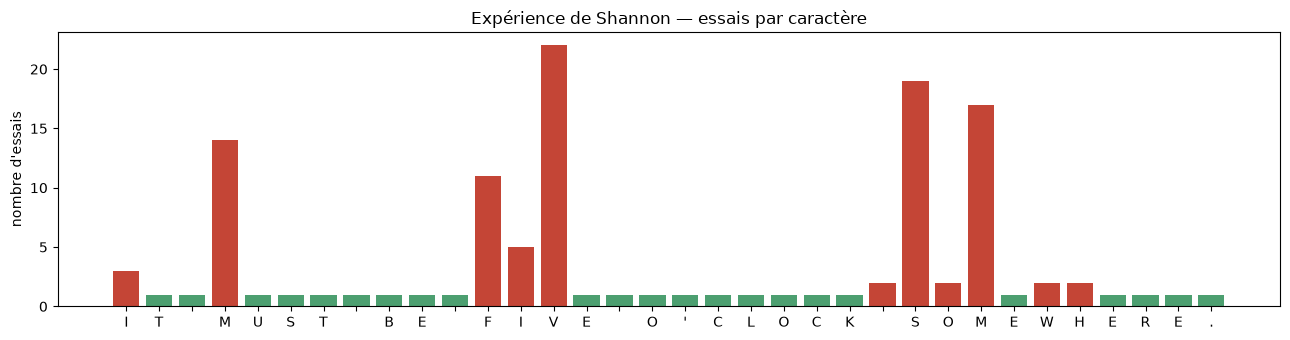

In [ ]:
phrase = "IT MUST BE FIVE O'CLOCK SOMEWHERE."
essais = np.array([3,1,1,14,1,1,1,1,1,1,1,11,5,22,1,1,1,1,1,1,1,1,1,
                   2,19,2,17,1,2,2,1,1,1,1])

print(f"Essais totaux       : {essais.sum()} pour {len(essais)} caractères "
      f"({essais.mean():.2f} par caractère)")
print(f"Devinés du 1er coup : {np.sum(essais == 1)} sur {len(essais)}")
print(f"Bornes données par l'expérience : 1.2178 – 1.7921 bits/caractère")
print(f"Modèle d'ordre 0 (Q1)           : {entropie_anglais:.4f} bits/caractère")

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(range(len(essais)), essais,
       color=np.where(essais > 1, '#C44536', '#4C9F70'))
ax.set_xticks(range(len(phrase))); ax.set_xticklabels(list(phrase))
ax.set_ylabel("nombre d'essais")
ax.set_title("Expérience de Shannon — essais par caractère")
plt.tight_layout(); plt.show()

J'ai fait l'expérience sur la phrase "IT MUST BE FIVE O'CLOCK SOMEWHERE.",
soit 34 caractères, et il m'a fallu 122 essais au total, c'est à dire 3.6 essais
par caractère en moyenne. À titre de comparaison, deviner au hasard dans un
alphabet de 29 caractères en demanderait environ 15.

Ce qui frappe en regardant le détail, c'est que la difficulté n'est pas répartie
du tout : 23 caractères sur 34 ont été trouvés du premier coup. Les essais se
concentrent sur une poignée de positions, et toujours les mêmes : le M de MUST
(14 essais), le F et le V de FIVE (11 et 22), le S de SOMEWHERE (19), le M qui
suit (17). Autrement dit, c'est le début des mots qui coûte cher. Une fois les
premières lettres posées, la suite ne demande plus aucun effort, le E final de
FIVE et toute la fin de SOMEWHERE sont trouvés du premier coup, et O'CLOCK en
entier également.

C'est exactement ce que décrit la théorie : l'information est concentrée aux
endroits où le contexte ne contraint pas encore le texte, et le reste n'est que
redondance. Mon modèle d'ordre 0 de la Q1 ignore totalement ça, puisqu'il traite
chaque lettre comme indépendante de ses voisines, d'où les 4.18 bits par
caractère qu'il annonce.

L'expérience donne une entropie comprise entre 1.22 et 1.79 bit par caractère,
bornes obtenues à partir de la distribution du nombre d'essais. C'est trois fois
moins que le modèle d'ordre 0 de la Q1, et c'est cohérent avec la valeur
d'environ 1 bit généralement admise pour l'anglais.

On retrouve au passage le même mécanisme que les compresseurs du Hutter Prize de
la Q2 : prédire la suite à partir du contexte, et payer uniquement ce qui reste
imprévisible.

# Exercice 2 : Estimation d'un taux de désintégration (loi de Poisson)

Dans cet exercice, nous étudions le nombre d'événements observés par un détecteur mesurant les désintégrations d'un échantillon radioactif. Ce phénomène est modélisé par une loi de Poisson de paramètre inconnu $\lambda^*$. L'objectif est d'établir les fondements théoriques de cette distribution (moments et cumulants) afin de pouvoir estimer $\lambda^*$ numériquement à partir de mesures indépendantes et d'étudier les probabilités de grandes fluctuations.

In [ ]:
import math

lambda_star = 3.0

## Question 1 : Fonction génératrice des moments et des cumulants

**a) Expression de $M_X(t)$ sous forme de somme**

Par définition en probabilités, l'espérance mathématique d'une fonction $g(X)$ pour une variable aléatoire discrète prenant ses valeurs dans $\mathbb{N}$ est donnée par :
$$\mathbb{E}[g(X)] = \sum_{k=0}^{\infty} g(k) \mathbb{P}(X=k)$$

Ici, la fonction dont on cherche l'espérance est $g(X) = e^{tX}$. L'énoncé nous donne la formule de la loi de Poisson : $\mathbb{P}(X=k) = e^{-\lambda^*} \frac{(\lambda^*)^k}{k!}$.

En substituant ces deux éléments dans la définition de l'espérance, on obtient la somme suivante :
$$M_X(t) = \mathbb{E}[e^{tX}] = \sum_{k=0}^{\infty} e^{tk} \left( e^{-\lambda^*} \frac{(\lambda^*)^k}{k!} \right)$$

**b) Reconnaissance du développement en série**

On factorise le terme $e^{-\lambda^*}$, qui ne dépend pas de $k$, puis on regroupe les puissances de $k$ :

$$M_X(t) = \sum_{k=0}^{\infty} e^{tk} \left( e^{-\lambda^*} \frac{(\lambda^*)^k}{k!} \right) = e^{-\lambda^*} \sum_{k=0}^{\infty} \frac{(e^t)^k (\lambda^*)^k}{k!} = e^{-\lambda^*} \sum_{k=0}^{\infty} \frac{(\lambda^* e^t)^k}{k!}$$

On reconnaît la série de Taylor de l'exponentielle, $\sum_{k=0}^{\infty} \frac{x^k}{k!} = e^x$, avec ici $x = \lambda^* e^t$. Cette série converge pour tout réel $x$, donc $M_X(t)$ est définie pour tout $t \in \mathbb{R}$ :

$$M_X(t) = e^{-\lambda^*} e^{\lambda^* e^t}$$

On obtient le résultat demandé :

$$M_X(t) = e^{\lambda^* e^t - \lambda^*} = e^{\lambda^*(e^t - 1)}$$

**c) Fonction génératrice des cumulants (CGM), moyenne et variance**

La CGM est définie par l'énoncé comme $\kappa_X(t) = \log(M_X(t))$. On trouve alors :
$$\kappa_X(t) = \log\left(e^{\lambda^*(e^t - 1)}\right) = \lambda^*(e^t - 1)$$

Pour trouver la moyenne $\mathbb{E}[X] = \kappa_X'(0)$, on dérive par rapport à $t$ :
$$\kappa_X'(t) = \lambda^* e^t \quad\Longrightarrow\quad \mathbb{E}[X] = \kappa_X'(0) = \lambda^*$$

Pour la variance $\mathrm{Var}(X) = \kappa_X''(0)$, on dérive une seconde fois :
$$\kappa_X''(t) = \lambda^* e^t \quad\Longrightarrow\quad \mathrm{Var}(X) = \kappa_X''(0) = \lambda^*$$

**Remarque.** Pour une loi de Poisson, la moyenne et la variance sont égales : $\mathbb{E}[X] = \mathrm{Var}(X) = \lambda^*$. C'est en fait vrai pour tous les cumulants : $\kappa_X^{(n)}(t) = \lambda^* e^t$ pour tout $n \geq 1$, donc le $n$-ième cumulant vaut $\lambda^*$ pour tout $n$. Une loi de Poisson est donc entièrement déterminée par son seul paramètre $\lambda^*$.

Conséquences utiles pour la suite :
- L'écart-type vaut $\sqrt{\lambda^*}$, donc les fluctuations relatives sont $\sigma/\mu = 1/\sqrt{\lambda^*}$ : elles diminuent quand le taux de comptage augmente (bruit de comptage, ou « shot noise »).
- Sur des données, vérifier que la variance empirique est proche de la moyenne empirique est un premier test de compatibilité avec une loi de Poisson.
- Ce résultat donne directement $\mathrm{Var}(\hat\lambda_N) = \lambda^*/N$ en Q3.


## Question 2 : Génération de données
Pour générer les variables aléatoires $X_i$ souivant la loi de Poisson, le code suivant va être utilisé :

In [ ]:
def generer_poisson_knuth_unitaire(lam):
    """
    Génère une unique variable aléatoire suivant une loi de Poisson 
    de paramètre lam en utilisant la méthode de Knuth.
    """
    L = math.exp(-lam)
    k = 0
    p = 1.0
    
    while True:
        p *= np.random.uniform(0.0, 1.0)
        if p <= L:
            break
        k += 1
        
    return k

def generer_echantillon_poisson_knuth(lam, taille):
    """
    Génère un échantillon de variables aléatoires de Poisson via Knuth.
    """
    return np.array([generer_poisson_knuth_unitaire(lam) for _ in range(taille)])

# Démonstration de la méthode de Knuth pour Q2
N_q2 = 1000
donnees_X_knuth = generer_echantillon_poisson_knuth(lambda_star, N_q2)
print(donnees_X_knuth)

[ 1  2  3  3  6  5  2  2  5  4  3  2  7  3  7  4  3  2  2  1  4  0  7  0
  2  1  1  4  3  8  5  0  2  4  4  2  4  6  3  0  2  1  1  3 11  2  1  2
  8  2  6  4  1  5  1  0  1  1  3  5  5  2  1  3  2  4  5  3  3  1  3  2
  5  3  3  4  2  6  3  1  5  5  3  3  2  2  1  3  3  4  2  2  2  1  7  2
  3  3  0  2  3  1  6  1  1  3  1  5  2  4  4  2  4  3  1  5  5  5  1  5
  4  0  4  0  3  5  4  1  2  4  2  0  6  3  4  2  1  5  4  9  2  3  2  6
  4  2  3  3  2  3  3  3  3  2  1  2  2  4  2  3  4  9  4  2  2  1  3  2
  3  5  2  0  3  2  5  3  2  2  1  4  3  1  4  2  3  2  1  1  2  2  4  4
  5  1  1  0  2  1  3  1  1  1  3  3  4  1  2  8  1  1  3  2  3  2  1  5
  2  6  2  2  3  4  7  3  3  4  2  4  4  5  3  4  2  1  3  3  3  5  3  1
  1  6  2  3  3  2  2  9  2  2  1  2  2  1  5  0  0  1  0  4  1  3  0  5
  4  4  5  5  6  7  6  5  2  1  5  4  1  3  2  0  1  3  0  2  6  3  1  3
  1  5  5  5  5  4  4  3  7  3  3  4  3  2  2  2  2  6  3  1  3  4  1  5
  0  2  2  4  3  2  3  2  0  1  3  1  6  3  7  3  1

Cette méthode, appelée méthode de Knuth, est une approche classique pour générer des variables aléatoires suivant une loi de Poisson. Elle repose sur le fait que le nombre d'événements dans un intervalle de temps suit une distribution de Poisson, et utilise une boucle pour simuler le processus jusqu'à ce qu'un certain seuil soit atteint. Cepardant, cette méthode peut être inefficace pour des valeurs élevées de lambda, car le nombre d'itérations nécessaires peut devenir très grand. Pour des applications nécessitant la génération de grandes quantités de données ou des valeurs de lambda élevées, il est souvent préférable d'utiliser des méthodes plus efficaces, telle que la fonction suivante (disponible dans la bibliothèque NumPy) :

In [ ]:
np.random.poisson(lambda_star, N_q2)  # Génération d'un échantillon de Poisson avec numpy pour comparaison

array([2, 7, 2, 4, 4, 1, 5, 6, 0, 6, 2, 1, 5, 6, 1, 5, 4, 4, 3, 2, 2, 3,
       1, 6, 3, 1, 3, 2, 0, 0, 3, 3, 0, 6, 1, 3, 1, 3, 4, 3, 2, 7, 3, 7,
       3, 3, 2, 3, 3, 1, 3, 1, 2, 4, 3, 3, 2, 0, 4, 3, 3, 1, 2, 1, 3, 2,
       4, 1, 1, 2, 3, 1, 1, 0, 4, 4, 4, 4, 3, 1, 5, 3, 1, 6, 2, 3, 4, 4,
       3, 3, 6, 3, 3, 2, 1, 5, 0, 3, 3, 4, 2, 3, 5, 6, 9, 3, 2, 4, 2, 4,
       3, 5, 2, 4, 9, 0, 5, 1, 4, 3, 4, 3, 2, 3, 3, 1, 3, 3, 4, 4, 4, 3,
       4, 2, 2, 3, 1, 0, 4, 2, 2, 2, 2, 3, 1, 2, 2, 5, 6, 4, 1, 5, 3, 3,
       6, 3, 3, 5, 4, 3, 3, 4, 2, 4, 3, 3, 1, 1, 0, 3, 4, 2, 1, 1, 6, 8,
       5, 3, 4, 7, 4, 1, 3, 0, 2, 3, 1, 4, 1, 3, 2, 3, 1, 0, 1, 1, 1, 1,
       4, 4, 1, 5, 4, 2, 2, 2, 3, 4, 2, 5, 0, 6, 2, 1, 1, 1, 3, 1, 4, 3,
       2, 3, 1, 5, 3, 2, 3, 2, 1, 3, 3, 3, 3, 0, 6, 1, 6, 3, 1, 4, 4, 2,
       2, 2, 2, 3, 2, 0, 2, 0, 2, 4, 1, 4, 3, 3, 3, 5, 4, 3, 1, 4, 3, 2,
       2, 1, 5, 4, 4, 3, 5, 5, 1, 4, 3, 5, 3, 2, 5, 3, 4, 3, 2, 2, 3, 3,
       1, 3, 1, 3, 8, 3, 4, 4, 1, 4, 2, 0, 4, 1, 1,

## Question 3 : Estimateur de $\lambda^*$

Nous considérons l'estimateur empirique défini par la moyenne des observations : 
$$\hat{\lambda}(\{X\}_N) = \hat{\lambda}_N = \frac{1}{N}\sum_{i=1}^{N}X_i$$

**1. Moyenne de l'estimateur**

Par linéarité de l'espérance, la moyenne de l'estimateur se calcule ainsi :
$$\mathbb{E}[\hat{\lambda}_N] = \mathbb{E}\left[\frac{1}{N}\sum_{i=1}^{N}X_i\right] = \frac{1}{N}\sum_{i=1}^{N}\mathbb{E}[X_i]$$

Or, d'après la question 1, nous savons que l'espérance d'une variable de Poisson est $\mathbb{E}[X_i] = \lambda^*$. Ainsi :
$$\mathbb{E}[\hat{\lambda}_N] = \frac{1}{N} (N \lambda^*) = \lambda^*$$


**2. Variance de l'estimateur**

Puisque les mesures $X_1, ..., X_N$ sont indépendantes, la variance de leur somme est égale à la somme de leurs variances. on a :
$$Var(\hat{\lambda}_N) = Var\left(\frac{1}{N}\sum_{i=1}^{N}X_i\right) = \frac{1}{N^2}\sum_{i=1}^{N}Var(X_i)$$

Sachant que $Var(X_i) = \lambda^*$, on obtient :
$$Var(\hat{\lambda}_N) = \frac{1}{N^2} (N \lambda^*) = \frac{\lambda^*}{N}$$

**3. Erreur typique**

L'erreur typique correspond à l'écart-type de l'estimateur :
$$\sigma_{\hat{\lambda}} = \sqrt{Var(\hat{\lambda}_N)} = \sqrt{\frac{\lambda^*}{N}} = \frac{\sqrt{\lambda^*}}{\sqrt{N}}$$


## Question 4 : Convergence Numérique

### Partie I : Convergence de $\hat{\lambda}$

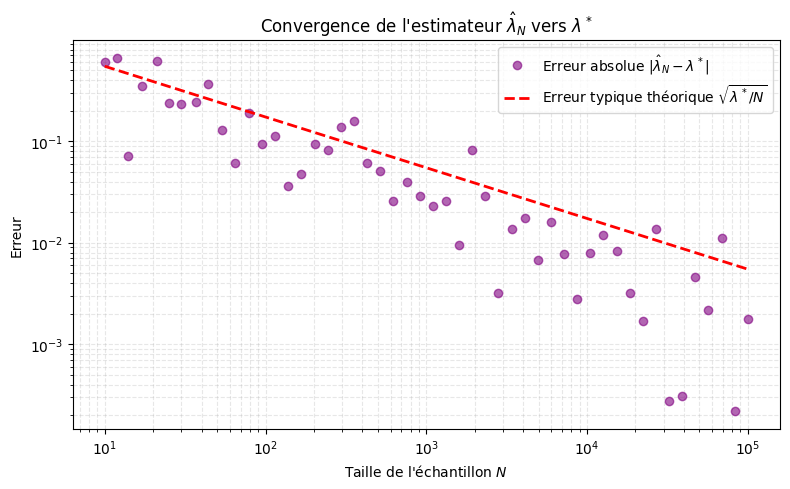

In [ ]:
# On génère un tableau de valeurs pour N espacées logarithmiquement
valeurs_N_conv = np.logspace(1, 5, 50, dtype=int)
erreurs_absolues = []

for N in valeurs_N_conv:
    # Pour chaque N, on effectue UNE seule expérience
    echantillon = np.random.poisson(lambda_star, N)
    lambda_chapeau = np.mean(echantillon)
    erreurs_absolues.append(np.abs(lambda_chapeau - lambda_star))

# Courbe de référence de l'erreur typique théorique (écart-type)
erreur_theorique = np.sqrt(lambda_star / valeurs_N_conv)

fig, ax1 = plt.subplots(figsize=(8, 5))

# Tracé de l'erreur absolue
ax1.plot(valeurs_N_conv, erreurs_absolues, marker='o', linestyle='none', color='purple', 
         alpha=0.6, label=r"Erreur absolue $\vert{}\hat{\lambda}_N - \lambda^*\vert{}$")
# Tracé de la référence 1/sqrt(N)
ax1.plot(valeurs_N_conv, erreur_theorique, linestyle='--', color='red', linewidth=2, 
         label=r"Erreur typique théorique $\sqrt{\lambda^*/N}$")

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlabel(r"Taille de l'échantillon $N$")
ax1.set_ylabel(r"Erreur")
ax1.set_title(r"Convergence de l'estimateur $\hat{\lambda}_N$ vers $\lambda^*$")
ax1.legend()
ax1.grid(True, which="both", ls="--", alpha=0.3)

plt.tight_layout()
plt.show()




Le premier graphique illustre l'évolution de l'erreur absolue $\vert{}\hat{\lambda}_N - \lambda^*\vert{}$ en fonction de la taille de l'échantillon $N$. L'observation démontre que :
1. **La non-monotonie :** Pour une unique réalisation par valeur de $N$, l'erreur absolue est soumise à la stochasticité. Elle fluctue de façon aléatoire et ne décroît pas de manière strictement monotone.
2. **La loi de convergence :** Ces fluctuations sont bornées et s'inscrivent dans une enveloppe dont la décroissance est dictée par l'erreur typique théorique (l'écart-type de l'estimateur) $\sigma_{\hat{\lambda}} = \sqrt{\frac{\lambda^*}{N}}$. La droite de référence en rouge sur l'échelle bi-logarithmique confirme que l'erreur converge vers $0$ selon un taux en $\mathcal{O}\left(\frac{1}{\sqrt{N}}\right)$. Cela vérifie numériquement la Loi Faible des Grands Nombres.

### Partie II : Distribution empirique de $\hat{\lambda}_N$


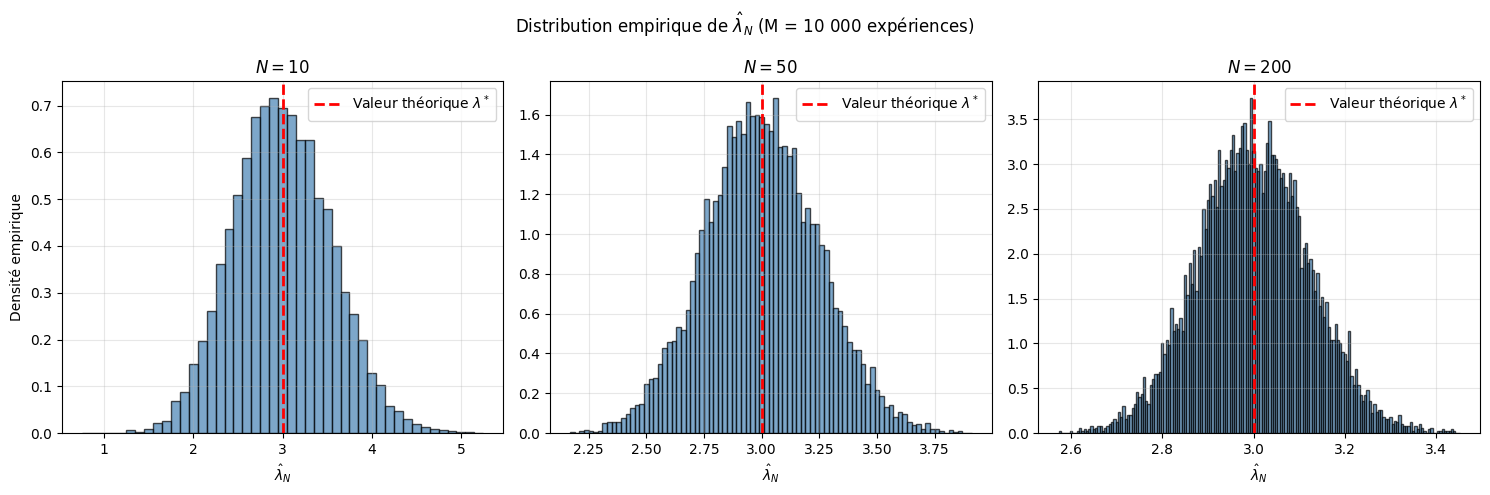

In [ ]:
M_exp = 10000  # Nombre de répétitions de l'expérience
valeurs_N_dist = [10, 50, 200]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(r"Distribution empirique de $\hat{\lambda}_N$ (M = 10 000 expériences)")

for i, N in enumerate(valeurs_N_dist):
    # Génération des échantillons
    echantillons = np.random.poisson(lambda_star, (M_exp, N))
    lambda_chapeau_dist = np.mean(echantillons, axis=1)

    val_min = np.min(lambda_chapeau_dist)
    val_max = np.max(lambda_chapeau_dist)
    largeur_bin = 1.0 / N
    # On centre les bins sur les valeurs multiples de 1/N
    bins_optimises = np.arange(val_min, val_max + largeur_bin, largeur_bin) - (largeur_bin / 2)
    
    axes[i].hist(lambda_chapeau_dist, bins=bins_optimises, density=True, 
                 color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].axvline(lambda_star, color='red', linestyle='dashed', linewidth=2, 
                    label=r"Valeur théorique $\lambda^*$")
    
    axes[i].set_title(r"$N = {}$".format(N))
    axes[i].set_xlabel(r"$\hat{\lambda}_N$")
    if i == 0:
        axes[i].set_ylabel("Densité empirique")
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

La seconde série de graphiques présente la distribution empirique de $\hat{\lambda}_N$ pour différentes valeurs fixes de $N$ ($10, 50, 200$), en répétant l'expérience $M = 10\,000$ fois. 

L'analyse de ces histogrammes met en évidence les phénomènes suivants :
1. **Convergence en probabilité (Loi des Grands Nombres) :** À mesure que $N$ augmente, la distribution empirique de $\hat{\lambda}_N$ se resserre de manière prononcée autour de la constante $\lambda^* = 3.0$. La base de l'histogramme rétrécit et son pic s'affine et s'élève, démontrant que la probabilité que $\hat{\lambda}_N$ s'écarte de $\lambda^*$ tend vers zéro. L'estimateur $\hat{\lambda}_N$ tend bien vers une constante, et non vers une loi de probabilité distribuée.
2. **Distinction avec le Théorème Central Limite (TCL) :** Il est erroné de déduire directement de ces graphiques que la moyenne tend vers une loi normale. Le rétrécissement de la variance, bien visible ici ($Var = \lambda^*/N$), correspond à la Loi des Grands Nombres. C'est uniquement par l'application d'un facteur de dilatation $\sqrt{N}$ que la variable centrée $\sqrt{N}(\hat{\lambda}_N - \lambda^*)$ est stabilisée pour tendre de manière asymptotique vers une loi Normale standardisée, propriété qui sera exploitée à la question 5.

## Q5. Théorème Central Limite

**Rappel du Théorème Central Limite (TCL) :**
Soit une suite $X_{1}, X_{2}, \dots, X_{N}$ de variables aléatoires indépendantes et identiquement distribuées (i.i.d.), d'espérance $\mu = \mathbb{E}[X]$ et de variance finie $\sigma^{2} = Var(X)$. Le Théorème Central Limite stipule que la variable aléatoire centrée et dilatée d'un facteur $\sqrt{N}$ converge en loi vers une distribution normale de moyenne nulle et de variance $\sigma^{2}$ lorsque $N \to \infty$ :
$$ \sqrt{N}(\hat{\lambda}_{N} - \mu) \xrightarrow{\mathcal{L}} \mathcal{N}(0, \sigma^{2}) $$

**Application au cadre de l'exercice :**
Les données $X_{i}$ suivent une loi de Poisson de paramètre $\lambda^{*}$. Selon les propriétés de cette loi, l'espérance et la variance sont égales : $\mu = \lambda^{*}$ et $\sigma^{2} = \lambda^{*}$.
En appliquant le TCL à l'estimateur $\hat{\lambda}_{N}$, on obtient la convergence suivante :
$$ \sqrt{N}(\hat{\lambda}_{N} - \lambda^{*}) \xrightarrow{\mathcal{L}} \mathcal{N}(0, \lambda^{*}) $$

**Loi limite de la variable $S_{N}$ :**
L'énoncé définit la variable $S_{N} = \sqrt{N}\hat{\lambda}_{N}$. En réarrangeant l'expression issue du TCL, la relation devient :
$$ S_{N} - \sqrt{N}\lambda^{*} \xrightarrow{\mathcal{L}} \mathcal{N}(0, \lambda^{*}) $$
Par conséquent la variable $S_{N}$ suit une loi normale telle que :
$$ S_{N} \sim \mathcal{N}(\sqrt{N}\lambda^{*}, \lambda^{*}) $$

**Signification pour la loi de l'estimateur $\hat{\lambda}_{N}$ :**
La convergence établie par le TCL signifie que pour un échantillon de taille $N$ suffisamment grande, la distribution empirique de l'estimateur $\hat{\lambda}_{N}$  peut être approximée par une loi normale :
$$ \hat{\lambda}_{N} \sim \mathcal{N}\left(\lambda^{*}, \frac{\lambda^{*}}{N}\right) $$

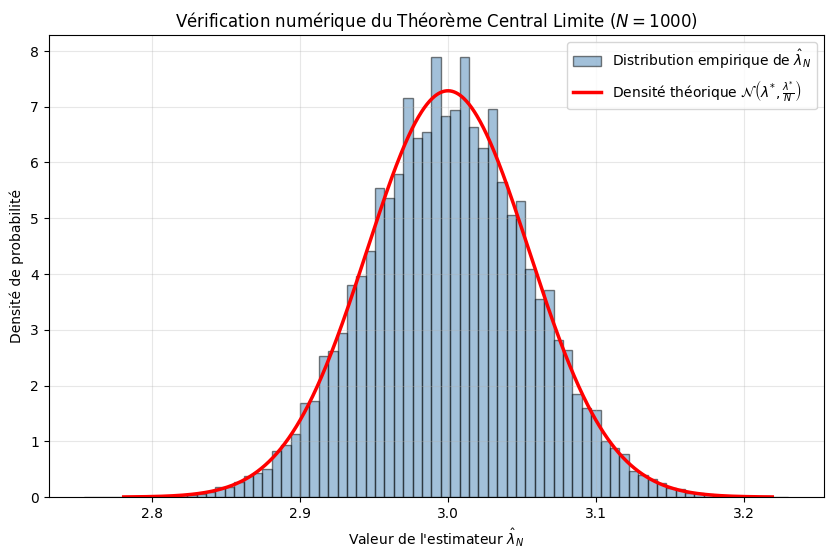

In [ ]:
# Fixation stricte des paramètres pour l'analyse locale
N_tcl = 1000
M_tcl = 100000

echantillons_tcl = np.random.poisson(lambda_star, (M_tcl, N_tcl))
lambda_hat_tcl = np.mean(echantillons_tcl, axis=1)

plt.figure(figsize=(10, 6))

plt.hist(lambda_hat_tcl, bins=75, density=True, alpha=0.5, color='steelblue', 
         edgecolor='black', label=r"Distribution empirique de $\hat{\lambda}_{N}$")

# Modélisation théorique
mu = lambda_star
sigma = np.sqrt(lambda_star / N_tcl)
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma)**2)

plt.plot(x, y, color='red', linewidth=2.5, 
         label=r"Densité théorique $\mathcal{N}\left(\lambda^{*}, \frac{\lambda^{*}}{N}\right)$")

plt.xlabel(r"Valeur de l'estimateur $\hat{\lambda}_{N}$")
plt.ylabel(r"Densité de probabilité")
plt.title(r"Vérification numérique du Théorème Central Limite ($N = {}$)".format(N_tcl))
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()
plt.close()

On voit distinctement sur le graphe que pour $N$ suffisamment grand (ici $N = 1000$), l'histogramme obtenu épouse le contour de la courbe gaussienne rouge, qui est la loi attendue par le TCL appliqué à notre problème. La vérification numérique est donc effectuée.

## Question 6 : Grandes fluctuations et fonction de taux $I(s)$

D'après le théorème de Cramér, la fonction de taux est définie par :
$$I(s) = \sup_{t \in \mathbb{R}} \{ts - \kappa_X(t)\}$$

En utilisant l'expression de la fonction génératrice des cumulants trouvée à la question 1, $\kappa_X(t) = \lambda^*(e^t - 1)$ :
$$I(s) = \sup_{t \in \mathbb{R}} \{ts - \lambda^*(e^t - 1)\}$$

**Le supremum est atteint en un unique point.** Posons $f(t) = ts - \lambda^*(e^t - 1)$. Sa dérivée seconde est
$$f''(t) = -\lambda^* e^t < 0 \quad \text{pour tout } t,$$
donc $f$ est strictement concave : si elle a un point critique, c'est son unique maximum global.

**Cas $s > 0$.** On annule la dérivée :
$$f'(t) = s - \lambda^* e^{t^*} = 0 \quad\Longrightarrow\quad e^{t^*} = \frac{s}{\lambda^*} \quad\Longrightarrow\quad t^* = \log\left(\frac{s}{\lambda^*}\right)$$
(ce point existe car $s/\lambda^* > 0$). On substitue dans $f$ :
$$I(s) = s \log\left(\frac{s}{\lambda^*}\right) - \lambda^*\left(e^{\log(s/\lambda^*)} - 1\right) = s \log\left(\frac{s}{\lambda^*}\right) - \lambda^*\left(\frac{s}{\lambda^{*}} - 1\right)$$

$$\boxed{I(s) = s \log\left(\frac{s}{\lambda^*}\right) - s + \lambda^*}$$

**Cas limites.**
- $s = 0$ : $f(t) = -\lambda^*(e^t - 1)$ est maximale quand $t \to -\infty$, d'où $I(0) = \lambda^*$. C'est cohérent avec la limite de la formule, car $s\log s \to 0$ quand $s \to 0$. Physiquement, $P(\hat\lambda_N = 0) = e^{-N\lambda^*}$.
- $s < 0$ : $f(t) \to +\infty$ quand $t \to -\infty$, donc $I(s) = +\infty$. C'est normal : $\hat\lambda_N \geq 0$ est impossible à rendre négatif.

**Vérification.** $I(\lambda^*) = 0$ et $I(s) > 0$ pour $s \neq \lambda^*$ (la valeur la plus probable est la moyenne), ce qui est cohérent avec la loi des grands nombres.

## Question 7 : Développement autour de la moyenne et lien avec le TCL

Pour faire le lien avec le TCL et étudier les petites fluctuations autour de la moyenne, nous effectuons un développement de Taylor de la fonction de taux $I(s)$ au voisinage de $s = \lambda^*$. 

**1. Calcul des dérivées évaluées en $\lambda^*$**

*   **Ordre 0 :** 
    $$I(\lambda^*) = \lambda^* \log(1) - \lambda^* + \lambda^* = 0$$
*   **Dérivée 1ère :** 
    $$I'(s) = 1 \cdot \log\left(\frac{s}{\lambda^*}\right) + s \cdot \left(\frac{1}{s/\lambda^*} \cdot \frac{1}{\lambda^*}\right) - 1 = \log\left(\frac{s}{\lambda^*}\right) + 1 - 1 = \log\left(\frac{s}{\lambda^*}\right)$$
    Évaluée en $\lambda^*$ : $I'(\lambda^*) = \log(1) = 0$
*   **Dérivée 2ème :** 
    $$I''(s) = \frac{1}{s}$$
    Évaluée en $\lambda^*$ : $I''(\lambda^*) = \frac{1}{\lambda^*}$
*   Dérivée 3ème : $$I'''(s) = -\frac{1}{s^2}$$
    Évaluée en $\lambda^*$ : $I'''(\lambda^*) = -\frac{1}{(\lambda^*)^2}$

**2. Développement de Taylor et approximation Gaussienne**

On peut alors ecrire :
$$I(s) \approx I(\lambda^*) + I'(\lambda^*)(s - \lambda^*) + \frac{1}{2}I''(\lambda^*)(s - \lambda^*)^2 + \frac{1}{6}I'''(\lambda^*)(s - \lambda^*)^3$$

$$I(s) \approx 0 + 0 + \frac{1}{2\lambda^*}(s - \lambda^*)^2 - \frac{1}{6(\lambda^*)^2}(s - \lambda^*)^3$$

Si l'on s'arrête au second ordre pour modéliser le voisinage immédiat de la moyenne, on obtient :
$$I(s) \approx \frac{(s - \lambda^*)^2}{2\lambda^*}$$

En réinjectant ce résultat d'ordre 2 dans la probabilité des grandes déviations $\mathbb{P}(\hat{\lambda}_N \approx s) \approx e^{-NI(s)}$, on trouve :
$$\mathbb{P}(\hat{\lambda}_N \approx s) \approx \exp\left( -N \frac{(s - \lambda^*)^2}{2\lambda^*} \right) = \exp\left( - \frac{(s - \lambda^*)^2}{2(\lambda^*/N)} \right)$$

On reconnaît très exactement le terme exponentiel de la densité d'une loi Normale (Gaussienne)($e^{-\frac{(x-\mu)^2}{2\sigma^2}}$) d'espérance $\mu = \lambda^*$ et de variance $\sigma^2 = \frac{\lambda^*}{N}$. En clair, le TCL revient simplement à approximer notre fonction $I(s)$ par une parabole, à condition de rester très près de la moyenne $\lambda^*$.

**3. Commentaires sur les déviations (terme d'ordre 3)**

Le TCL suggère que la distribution des erreurs est une "cloche" parfaitement symétrique. Cependant, si on s'éloigne de la moyenne, le terme d'ordre 3 $-\frac{(s - \lambda^*)^3}{6(\lambda^*)^2}$ ne peut plus être négligé :
*   **Asymétrie à droite ($s > \lambda^*$) :** L'écart est positif, le terme au cube reste positif. Avec le signe moins devant, cela vient faire baisser la valeur de $I(s)$. Puisque la probabilité est gérée par $e^{-N I(s)}$, une fonction de taux plus faible implique une probabilité exponentiellement plus grande. La vraie courbe s'étale donc plus loin vers la droite que ne le prévoit la Gaussienne.
*   **Asymétrie à gauche ($s < \lambda^*$) :** L'écart est négatif, et un nombre négatif au cube reste négatif. Les signes moins s'annulent, ce qui augmente $I(s)$. La probabilité s'effondre alors beaucoup plus vite.
*   **Conclusion :** L'approximation Gaussienne (le TCL) est une excellente approximation locale pour les petites fluctuations, mais elle sous-estime drastiquement la probabilité d'avoir d'importants pics de radioactivité (grandes déviations à droite) à cause de l'asymétrie inhérente à la loi de Poisson.

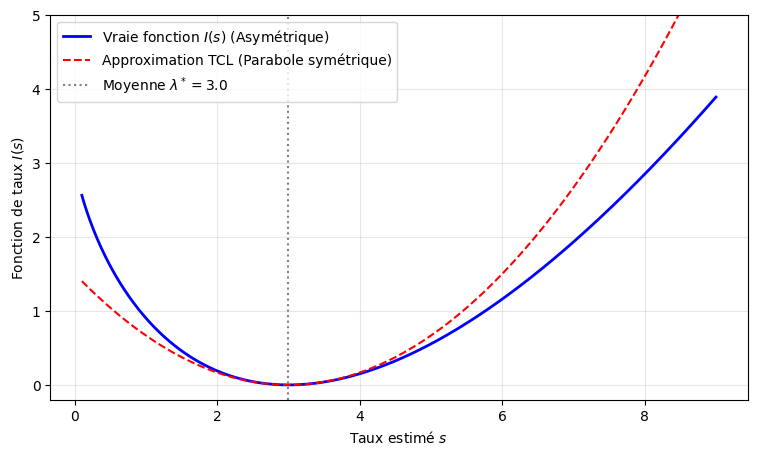

In [ ]:
s = np.linspace(0.1, 9, 500)
I_exact = s * np.log(s / lambda_star) - s + lambda_star
I_TCL = (s - lambda_star)**2 / (2 * lambda_star)

plt.figure(figsize=(9, 5))
plt.plot(s, I_exact, label='Vraie fonction $I(s)$ (Asymétrique)', color='blue', linewidth=2)
plt.plot(s, I_TCL, label='Approximation TCL (Parabole symétrique)', color='red', linestyle='--')

plt.axvline(lambda_star, color='grey', linestyle=':', label=f'Moyenne $\\lambda^* = {lambda_star}$')

plt.xlabel('Taux estimé $s$')
plt.ylabel('Fonction de taux $I(s)$')
plt.ylim(-0.2, 5)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## Question 8 : Vérification numérique

### Partie I : Comparaison histogramme de $S_N$ à la loi issue du TCL

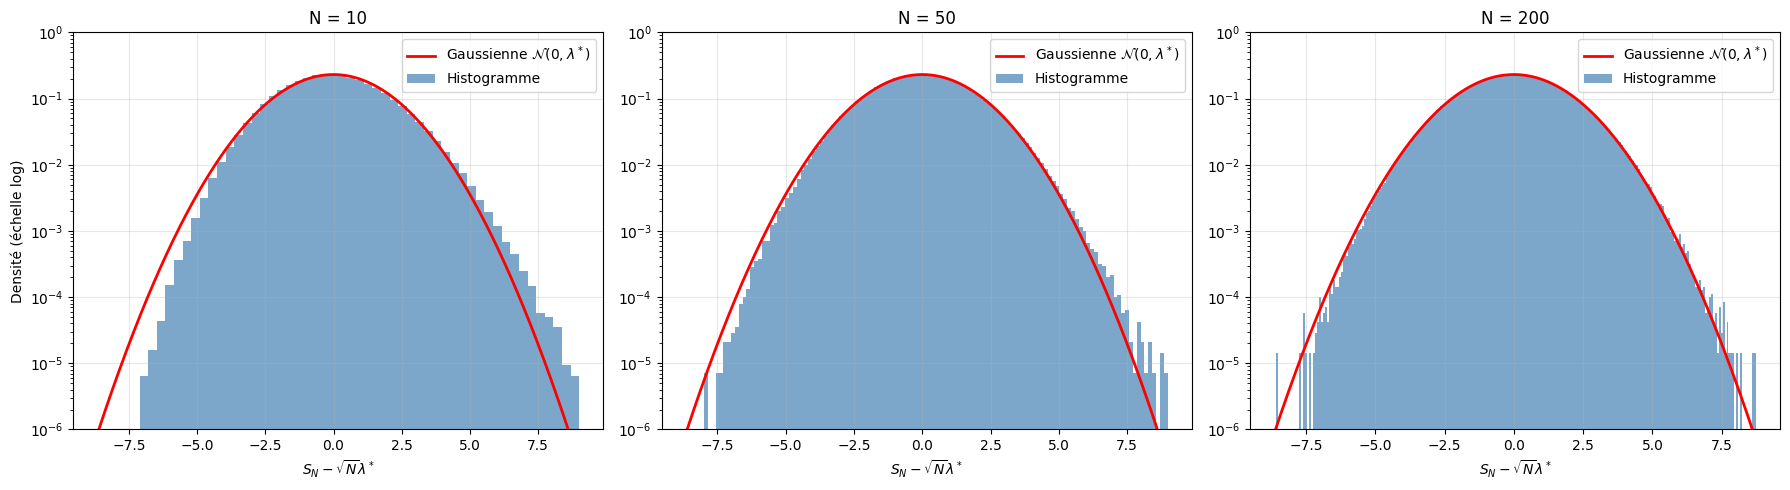

In [ ]:
valeurs_N = [10, 50, 200]
M = 1_000_000  # nombre d'expériences

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, N in enumerate(valeurs_N):
    # K = X_1 + ... + X_N suit une loi de Poisson(N lambda*) (voir Partie II)
    K = np.random.poisson(N * lambda_star, M)

    # S_N centré = sqrt(N)(lambda_hat - lambda*) = (K - N lambda*)/sqrt(N).
    # K est entier : S_N ne prend que des valeurs espacées de 1/sqrt(N).
    # On trace donc une barre par valeur possible (évite l'effet "peigne" des bins fixes).
    comptes = np.bincount(K)
    k = np.arange(len(comptes))
    m = comptes > 0
    pas = 1 / np.sqrt(N)
    axes[i].bar((k[m] - N * lambda_star) / np.sqrt(N), comptes[m] / M / pas, width=pas,
                color='steelblue', alpha=0.7, label="Histogramme")

    # Loi limite du TCL : N(0, lambda*)
    sigma = np.sqrt(lambda_star)
    x = np.linspace(-5 * sigma, 5 * sigma, 1000)
    axes[i].plot(x, np.exp(-x**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)), 'r',
                 linewidth=2, label=r"Gaussienne $\mathcal{N}(0,\lambda^*)$")

    axes[i].set_yscale('log')
    axes[i].set_ylim(1e-6, 1)
    axes[i].set_title(f"N = {N}")
    axes[i].set_xlabel(r"$S_N - \sqrt{N}\lambda^*$")
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

axes[0].set_ylabel("Densité (échelle log)")
plt.tight_layout()
plt.show()

On trace l'histogramme de $S_N-\sqrt N\lambda^*$ (centré pour le comparer directement à $\mathcal N(0,\lambda^*)$) avec $M=10^6$ expériences. Comme $\hat\lambda_N=K/N$ avec $K$ entier, $S_N$ ne prend que des valeurs espacées de $1/\sqrt N$ : on trace une barre par valeur possible plutôt qu'un nombre de bins fixe, qui produirait des cases vides.

- **Autour de la moyenne**, l'histogramme suit bien la gaussienne, déjà pour $N=10$ et de mieux en mieux quand $N$ augmente.
- **Dans les queues**, l'approximation gaussienne échoue : l'histogramme est au-dessus de la gaussienne à droite (elle sous-estime les gros excès) et en dessous à gauche. C'est l'asymétrie de la loi de Poisson (terme d'ordre 3 de $I(s)$, Q7).
- **Quand $N$ augmente**, la gaussienne reste valable sur une plage plus large, mais pour tout $N$ fini elle finit par échouer dans les queues.

### Partie II : Vérification numérique de la loi des grandes déviations

On veut vérifier que $-\frac1N\ln\mathbb P(\hat\lambda_N=s)$ se superpose à $I(s)$.

**Simulation.** La somme $K=\sum_i X_i$ de $N$ variables de Poisson($\lambda^*$) indépendantes a pour fonction génératrice $\left[e^{\lambda^*(e^t-1)}\right]^N=e^{N\lambda^*(e^t-1)}$ : c'est une Poisson($N\lambda^*$). On tire donc directement $K$ ($M=10^7$ fois) et on estime $\mathbb P(\hat\lambda_N=s)$ par la fréquence de $K=Ns$.

**Préfacteur.** La loi de Poisson exacte est $e^{-N\lambda^*}\frac{(N\lambda^*)^{Ns}}{(Ns)!}$ et la formule de Stirling donne $\mathbb P(\hat\lambda_N=s)\simeq \frac{e^{-NI(s)}}{\sqrt{2\pi Ns}}$. Donc $-\frac1N\ln\mathbb P \simeq I(s)+\frac{1}{2N}\ln(2\pi Ns)$ : le terme en plus est un préfacteur qui disparaît quand $N\to\infty$. On le retranche pour comparer à $I(s)$.

**Limite statistique.** Une valeur vue une seule fois correspond à $I\approx\ln(M)/N$ : on ne garde que les valeurs observées au moins 100 fois.

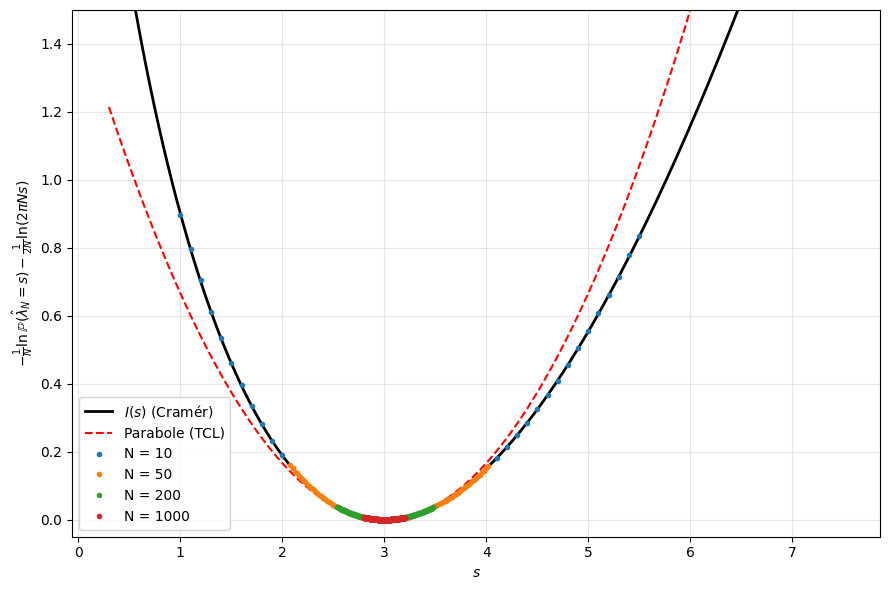

In [ ]:
valeurs_N_gd = [10, 50, 200, 1000]
M_gd = 10_000_000
c_min = 100   # on ne garde que les valeurs observées au moins c_min fois

s_th = np.linspace(0.3, 7.5, 500)
I_th = s_th * np.log(s_th / lambda_star) - s_th + lambda_star
I_tcl = (s_th - lambda_star)**2 / (2 * lambda_star)

plt.figure(figsize=(9, 6))
plt.plot(s_th, I_th, 'k-', linewidth=2, label=r"$I(s)$ (Cramér)")
plt.plot(s_th, I_tcl, 'r--', label="Parabole (TCL)")

for N in valeurs_N_gd:
    K = np.random.poisson(N * lambda_star, M_gd)   # K = somme de N Poisson(lambda*)
    comptes = np.bincount(K)
    k = np.arange(len(comptes))
    m = (comptes >= c_min) & (k >= 1)
    s = k[m] / N
    I_emp = -np.log(comptes[m] / M_gd) / N
    I_corrige = I_emp - np.log(2 * np.pi * N * s) / (2 * N)   # on retire le préfacteur de Stirling
    plt.plot(s, I_corrige, 'o', markersize=3, label=f"N = {N}")

plt.xlabel(r"$s$")
plt.ylabel(r"$-\frac{1}{N}\ln \mathbb{P}(\hat\lambda_N = s) - \frac{1}{2N}\ln(2\pi N s)$")
plt.ylim(-0.05, 1.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pour chaque $N$, les points (après retrait du préfacteur) tombent sur la courbe $I(s)$ : la loi $\mathbb P(\hat\lambda_N\approx s)\asymp e^{-NI(s)}$ est vérifiée, et la valeur de $N$ n'intervient pas. La parabole du TCL, elle, ne colle à $I(s)$ qu'au voisinage de $\lambda^*=3$ ; plus loin elle est au-dessus de $I(s)$ à droite et en dessous à gauche, comme prévu par le terme d'ordre 3.

**Limite :** avec $M=10^7$ on n'observe que les valeurs dont la probabilité est supérieure à $\sim 10^{-5}$, soit $I\lesssim\ln(M/c_{\min})/N$. Cette fenêtre se rétrécit quand $N$ augmente : pour $N=10$ on atteint de vraies grandes déviations ($s\in[1;5{,}5]$), pour $N=1000$ seulement $s\in[2{,}8;3{,}2]$.